In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [3]:
# ================================
# BLOCK 2: LOAD DATASET
# ================================

df = pd.read_csv("/content/adult.csv")

print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (48842, 15)

Data Types:
age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object

First 5 Rows:


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [4]:
# ================================
# BLOCK 3: REMOVE WHITESPACE
# ================================

for col in df.select_dtypes(include="object"):
    df[col] = df[col].str.strip()

print("Whitespace removed from all object columns.")

Whitespace removed from all object columns.


In [5]:
# ================================
# BLOCK 4: HANDLE MISSING VALUES
# ================================

df.replace("?", np.nan, inplace=True)

print("Missing values:")
print(df.isnull().sum())

Missing values:
age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64


In [6]:
# ================================
# BLOCK 5: DROP MISSING ROWS
# ================================

before = df.shape[0]

df.dropna(inplace=True)

after = df.shape[0]

print("Rows before dropping:", before)
print("Rows after dropping:", after)
print("Rows removed:", before - after)

print("\nNew Shape:", df.shape)

Rows before dropping: 48842
Rows after dropping: 45222
Rows removed: 3620

New Shape: (45222, 15)


In [7]:
# ================================
# BLOCK 6: DROP REDUNDANT COLUMNS
# ================================

df.drop(columns=["fnlwgt", "education"], inplace=True)

print("Columns after dropping fnlwgt and education:")
print(df.columns)

print("\nDataset Shape:", df.shape)

Columns after dropping fnlwgt and education:
Index(['age', 'workclass', 'educational-num', 'marital-status', 'occupation',
       'relationship', 'race', 'gender', 'capital-gain', 'capital-loss',
       'hours-per-week', 'native-country', 'income'],
      dtype='object')

Dataset Shape: (45222, 13)


In [8]:
# ================================
# BLOCK 7: ENCODE TARGET
# ================================

df["income"] = (df["income"] == ">50K").astype(int)

print("Income distribution:")
print(df["income"].value_counts())

print("\nIncome percentage:")
print(df["income"].value_counts(normalize=True) * 100)

Income distribution:
income
0    34014
1    11208
Name: count, dtype: int64

Income percentage:
income
0    75.215603
1    24.784397
Name: proportion, dtype: float64


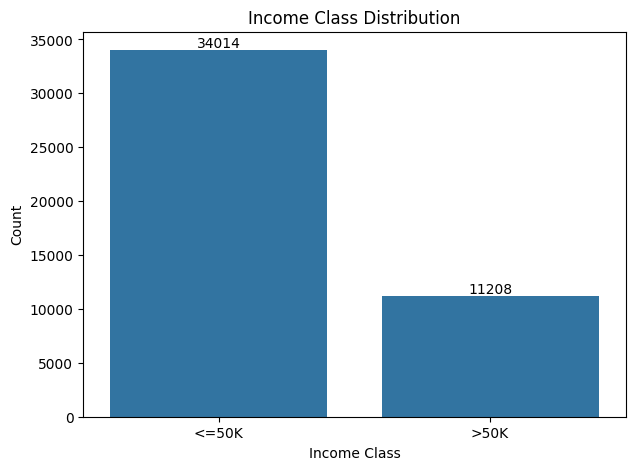

In [9]:
# ================================
# BLOCK 8: CLASS DISTRIBUTION
# ================================

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="income")

plt.title("Income Class Distribution")
plt.xlabel("Income Class")
plt.ylabel("Count")
plt.xticks([0, 1], ["<=50K", ">50K"])

# Bar annotations
for container in ax.containers:
    ax.bar_label(container)

plt.show()

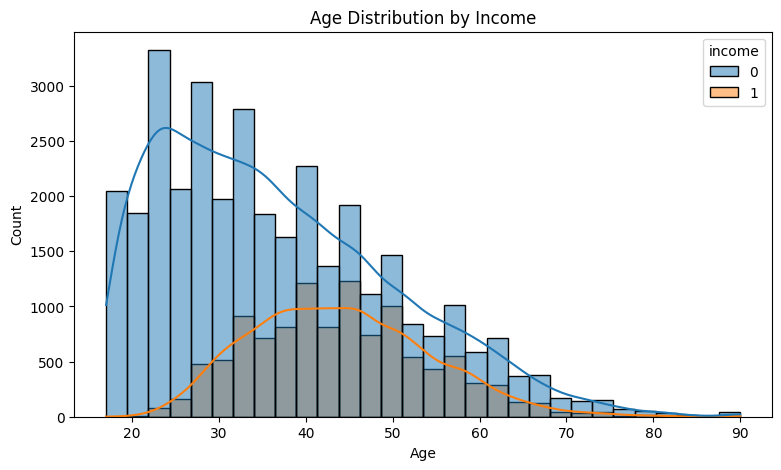

In [10]:
# ================================
# BLOCK 9: AGE DISTRIBUTION
# ================================

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="age",
    hue="income",
    bins=30,
    kde=True
)

plt.title("Age Distribution by Income")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

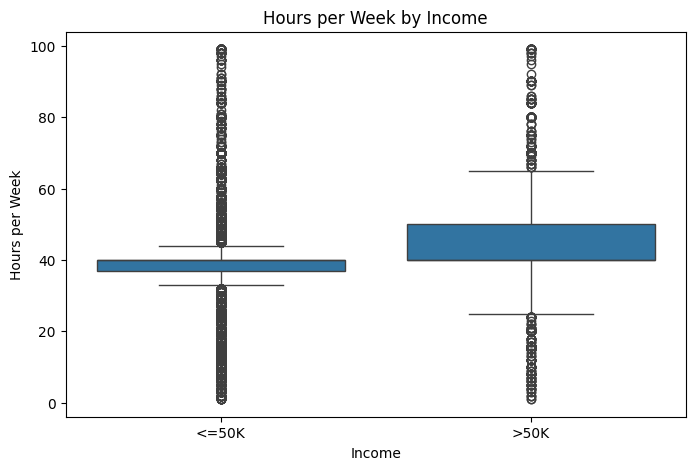

In [11]:
# ================================
# BLOCK 10: HOURS PER WEEK
# ================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="income",
    y="hours-per-week"
)

plt.title("Hours per Week by Income")
plt.xlabel("Income")
plt.ylabel("Hours per Week")
plt.xticks([0, 1], ["<=50K", ">50K"])

plt.show()

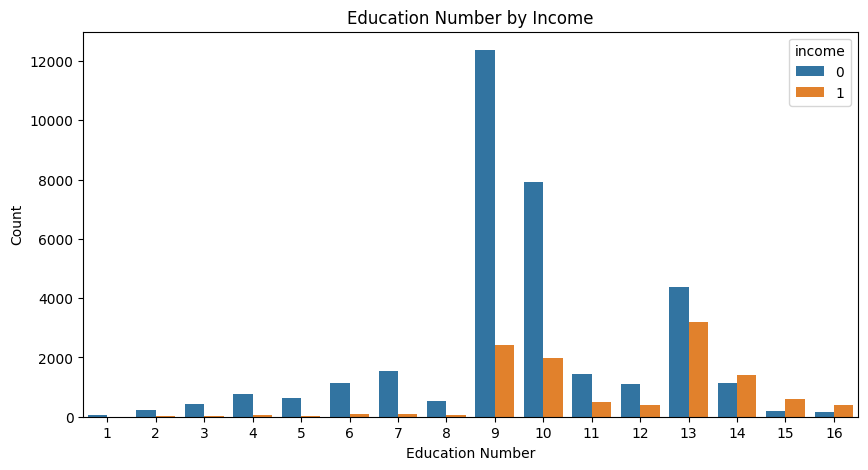

In [12]:
# ================================
# BLOCK 11: EDUCATION NUM BY INCOME
# ================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="educational-num",
    hue="income"
)

plt.title("Education Number by Income")
plt.xlabel("Education Number")
plt.ylabel("Count")

plt.show()

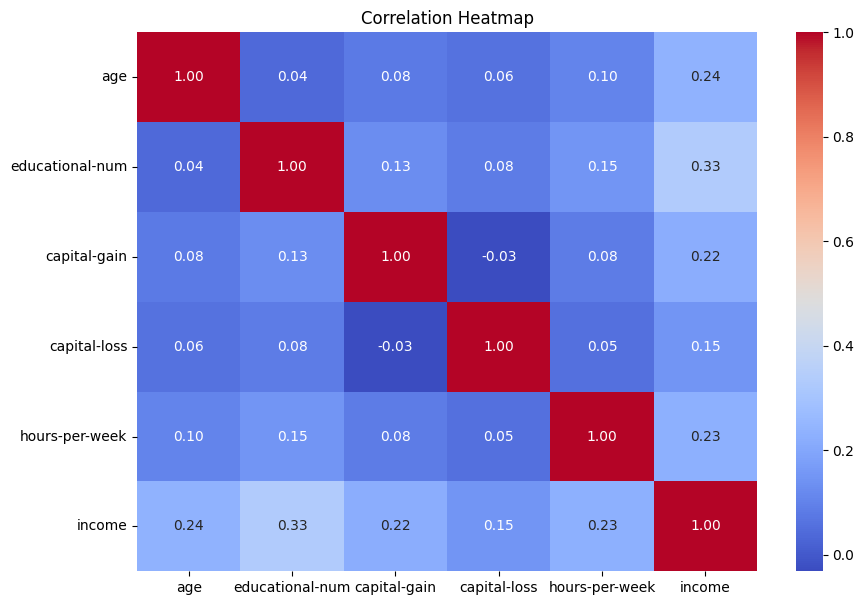

In [13]:
# ================================
# BLOCK 12: CORRELATION HEATMAP
# ================================

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [14]:
# ================================
# BLOCK 13: FEATURES AND TARGET
# ================================

X = df.drop("income", axis=1)
y = df["income"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (45222, 12)
y Shape: (45222,)


In [15]:
# ================================
# BLOCK 14: ONE-HOT ENCODING
# ================================

X = pd.get_dummies(X, drop_first=True)

print("Shape after One-Hot Encoding:", X.shape)

display(X.head())

Shape after One-Hot Encoding: (45222, 80)


,age,educational-num,capital-gain,capital-loss,hours-per-week,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,25,7,0,0,40,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,38,9,0,0,50,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,28,12,0,0,40,True,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,44,10,7688,0,40,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
5,34,6,0,0,30,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [16]:
# ================================
# BLOCK 15: SCALE NUMERIC FEATURES
# ================================

numeric_columns = [
    "age",
    "educational-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

scaler = StandardScaler()

X[numeric_columns] = scaler.fit_transform(X[numeric_columns])

print("Numeric features scaled successfully.")

display(X.head())

Numeric features scaled successfully.


,age,educational-num,capital-gain,capital-loss,hours-per-week,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,-1.024983,-1.221559,-0.146733,-0.21878,-0.078120,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,-0.041455,-0.438122,-0.146733,-0.21878,0.754701,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,-0.798015,0.737034,-0.146733,-0.21878,-0.078120,True,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,0.412481,-0.046403,0.877467,-0.21878,-0.078120,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
5,-0.344079,-1.613277,-0.146733,-0.21878,-0.910942,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [17]:
# ================================
# BLOCK 16: TRAIN TEST SPLIT
# ================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (36177, 80)
X_test : (9045, 80)
y_train: (36177,)
y_test : (9045,)


In [18]:
# ================================
# BLOCK 17: CHECK CLASS RATIO
# ================================

print("Original class ratio:")
print(y.value_counts(normalize=True))

print("\nTraining class ratio:")
print(y_train.value_counts(normalize=True))

print("\nTesting class ratio:")
print(y_test.value_counts(normalize=True))

Original class ratio:
income
0    0.752156
1    0.247844
Name: proportion, dtype: float64

Training class ratio:
income
0    0.752163
1    0.247837
Name: proportion, dtype: float64

Testing class ratio:
income
0    0.752128
1    0.247872
Name: proportion, dtype: float64


In [19]:
# ==========================================
# TASK 2.1: BUILD ANN FUNCTION
# ==========================================

def build_ann(
    input_dim,
    hidden_units=[128, 64],
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
):

    model = keras.Sequential()

    # First hidden layer
    model.add(
        layers.Dense(
            hidden_units[0],
            activation=None if use_batch_norm else activation,
            kernel_initializer=initializer,
            input_shape=(input_dim,)
        )
    )

    if use_batch_norm:
        model.add(layers.BatchNormalization())
        model.add(layers.Activation(activation))

    # Second hidden layer
    model.add(
        layers.Dense(
            hidden_units[1],
            activation=None if use_batch_norm else activation,
            kernel_initializer=initializer
        )
    )

    if use_batch_norm:
        model.add(layers.BatchNormalization())
        model.add(layers.Activation(activation))

    # Output layer
    model.add(
        layers.Dense(
            1,
            activation="sigmoid"
        )
    )

    # Optimizer
    if optimizer == "adam":
        opt = keras.optimizers.Adam()
    elif optimizer == "sgd":
        opt = keras.optimizers.SGD()
    elif optimizer == "rmsprop":
        opt = keras.optimizers.RMSprop()
    else:
        opt = optimizer

    model.compile(
        optimizer=opt,
        loss=loss,
        metrics=["accuracy"]
    )

    return model

In [20]:
# ==========================================
# TASK 2.2: BASELINE ANN
# ==========================================

model_base = build_ann(
    input_dim=X_train.shape[1]
)

model_base.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# ==========================================
# TASK 2.3: TRAIN BASELINE
# ==========================================

history_base = model_base.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8424 - loss: 0.3365 - val_accuracy: 0.8505 - val_loss: 0.3215
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8524 - loss: 0.3157 - val_accuracy: 0.8516 - val_loss: 0.3205
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8543 - loss: 0.3117 - val_accuracy: 0.8532 - val_loss: 0.3203
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8552 - loss: 0.3086 - val_accuracy: 0.8560 - val_loss: 0.3177
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8566 - loss: 0.3065 - val_accuracy: 0.8530 - val_loss: 0.3198
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8593 - loss: 0.3030 - val_accuracy: 0.8543 - val_loss: 0.3189
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8597 - loss: 0.3009 - val_accuracy: 0.8463 - val_loss: 0.3264
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8607 - loss: 0.2982 - val_accuracy: 0.

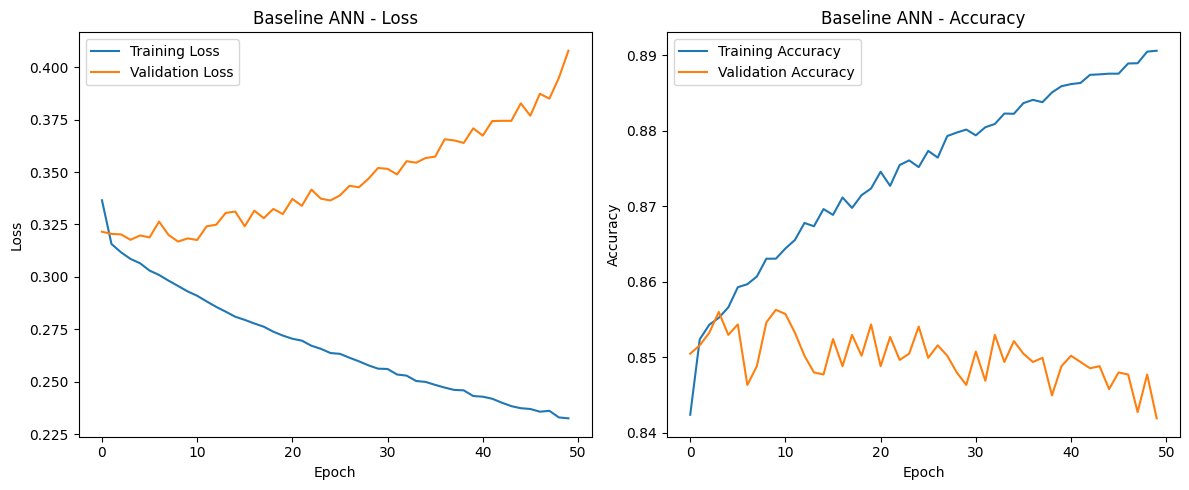

In [22]:
# ==========================================
# TASK 2.3: TRAINING CURVES
# ==========================================

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)

plt.plot(
    history_base.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_base.history["val_loss"],
    label="Validation Loss"
)

plt.title("Baseline ANN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


# Accuracy
plt.subplot(1, 2, 2)

plt.plot(
    history_base.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_base.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Baseline ANN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
# ==========================================
# TASK 2.4: EVALUATE BASELINE
# ==========================================

y_pred_prob = model_base.predict(X_test).flatten()

y_pred = (y_pred_prob > 0.5).astype(int)

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["<=50K", ">50K"]
    )
)

283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.90      0.89      6803
        >50K       0.68      0.68      0.68      2242

    accuracy                           0.84      9045
   macro avg       0.79      0.79      0.79      9045
weighted avg       0.84      0.84      0.84      9045



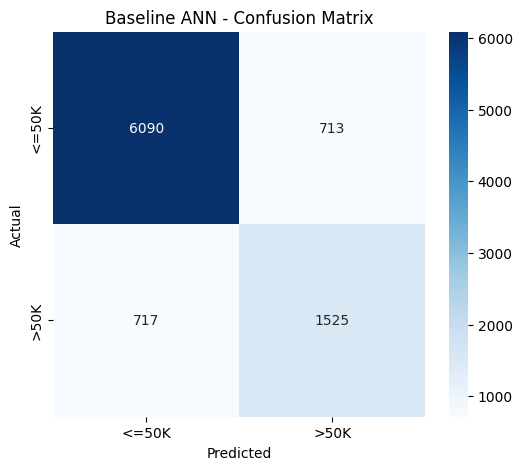

In [24]:
# ==========================================
# TASK 2.4: CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.title("Baseline ANN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [25]:
# ==========================================
# TASK 2.4: CLASS 1 METRICS
# ==========================================

precision_base = precision_score(y_test, y_pred)
recall_base = recall_score(y_test, y_pred)
f1_base = f1_score(y_test, y_pred)
auc_base = roc_auc_score(y_test, y_pred_prob)

print("Baseline Metrics")
print("-------------------------")
print("Precision (Class 1):", precision_base)
print("Recall    (Class 1):", recall_base)
print("F1 Score  (Class 1):", f1_base)
print("ROC-AUC:", auc_base)

Baseline Metrics
-------------------------
Precision (Class 1): 0.6814119749776586
Recall    (Class 1): 0.6801962533452275
F1 Score  (Class 1): 0.6808035714285714
ROC-AUC: 0.8913564396669728


In [26]:
# ==========================================
# TASK 3.1: ACTIVATION COMPARISON
# ==========================================

activations = ["relu", "tanh", "sigmoid", "elu"]

models_activation = {}
histories_activation = {}

for activation in activations:

    print("\nTraining:", activation)

    model = build_ann(
        input_dim=X_train.shape[1],
        activation=activation
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    models_activation[activation] = model
    histories_activation[activation] = history

print("\nAll activation models trained!")


Training: relu


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training: tanh


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training: sigmoid


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training: elu


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



All activation models trained!


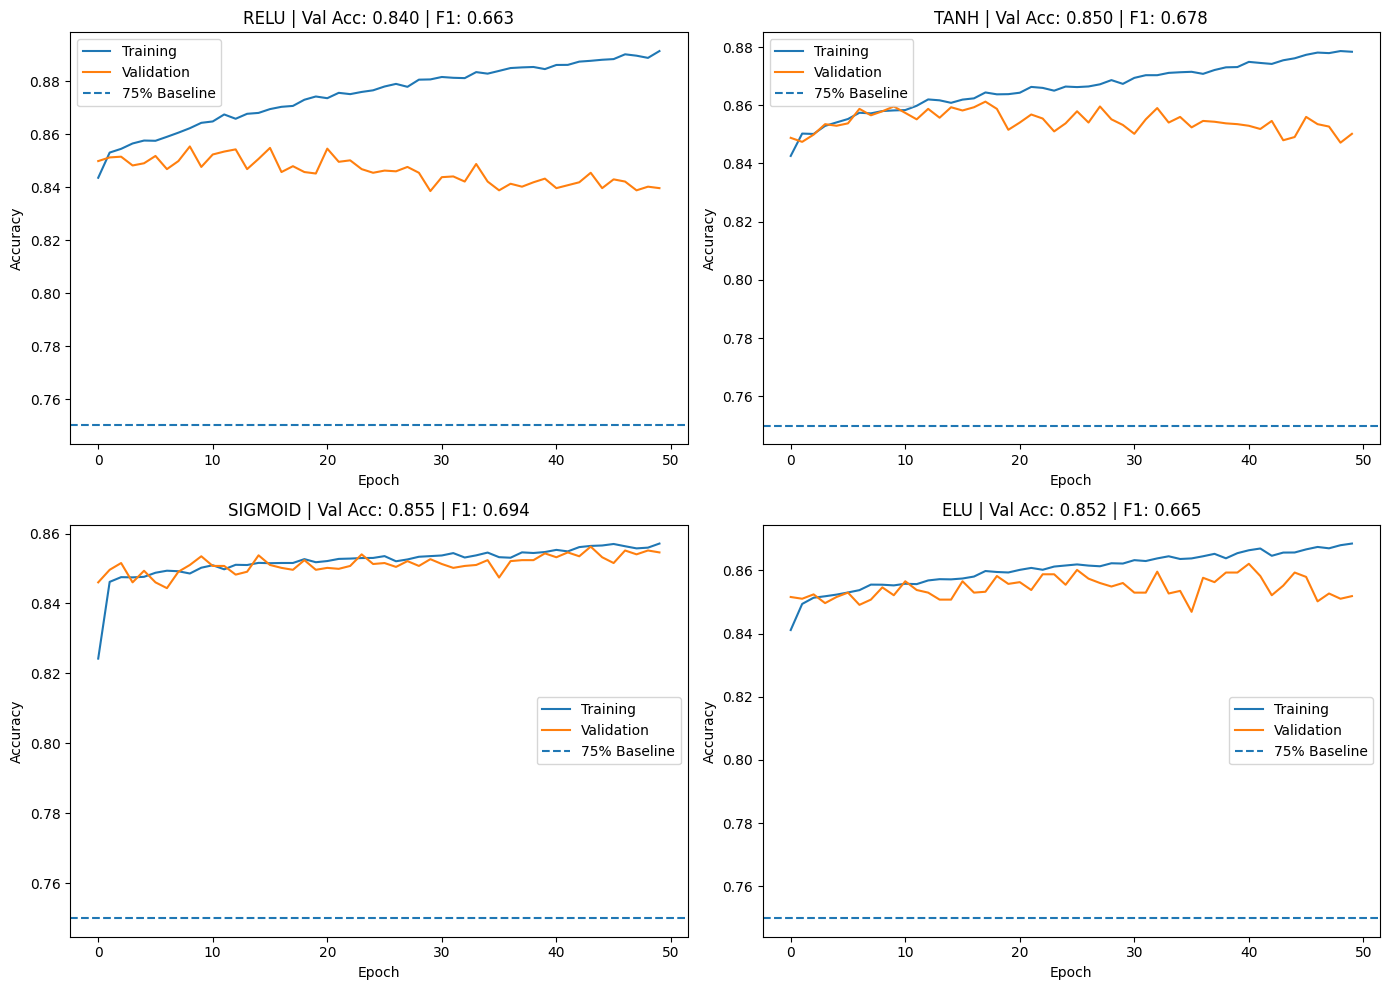

In [27]:
# ==========================================
# TASK 3.2: ACTIVATION COMPARISON
# ==========================================

plt.figure(figsize=(14, 10))

for i, activation in enumerate(activations):

    history = histories_activation[activation]
    model = models_activation[activation]

    y_prob = model.predict(X_test, verbose=0).flatten()
    y_pred_act = (y_prob > 0.5).astype(int)

    f1 = f1_score(y_test, y_pred_act)

    plt.subplot(2, 2, i + 1)

    plt.plot(
        history.history["accuracy"],
        label="Training"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation"
    )

    plt.axhline(
        0.75,
        linestyle="--",
        label="75% Baseline"
    )

    final_val_acc = history.history["val_accuracy"][-1]

    plt.title(
        f"{activation.upper()} | "
        f"Val Acc: {final_val_acc:.3f} | "
        f"F1: {f1:.3f}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

plt.tight_layout()
plt.show()

In [30]:
# ==========================================
# TASK 3.3: RELU DEAD NEURON CHECK
# ==========================================

model_relu = models_activation["relu"]

# Safely extract activations by calling the first layer directly on the test data
first_layer = model_relu.layers[0]
# Explicitly cast to float32 to prevent 'object' type conversion failure
inputs_float = X_test[:500].values.astype(np.float32)
activations_relu = first_layer(inputs_float).numpy()

dead_fraction = np.mean(activations_relu == 0)

print("Dead Neuron Fraction:", dead_fraction)

Dead Neuron Fraction: 0.61715625


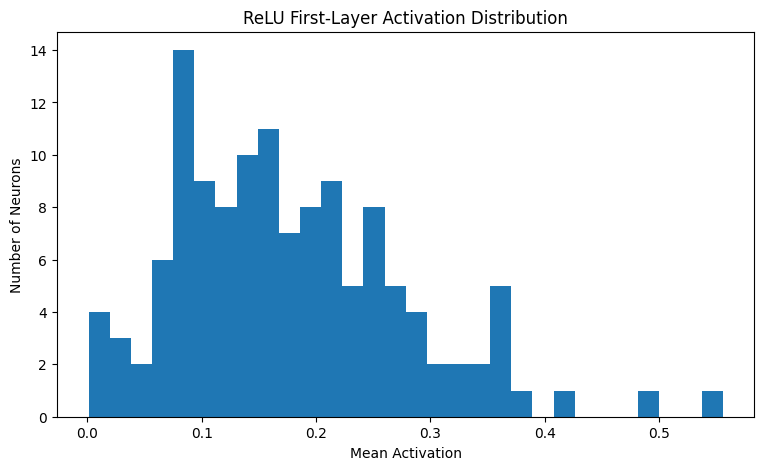

In [31]:
# ==========================================
# TASK 3.3: ACTIVATION DISTRIBUTION
# ==========================================

mean_activation = np.mean(
    activations_relu,
    axis=0
)

plt.figure(figsize=(9, 5))

plt.hist(
    mean_activation,
    bins=30
)

plt.title("ReLU First-Layer Activation Distribution")
plt.xlabel("Mean Activation")
plt.ylabel("Number of Neurons")

plt.show()

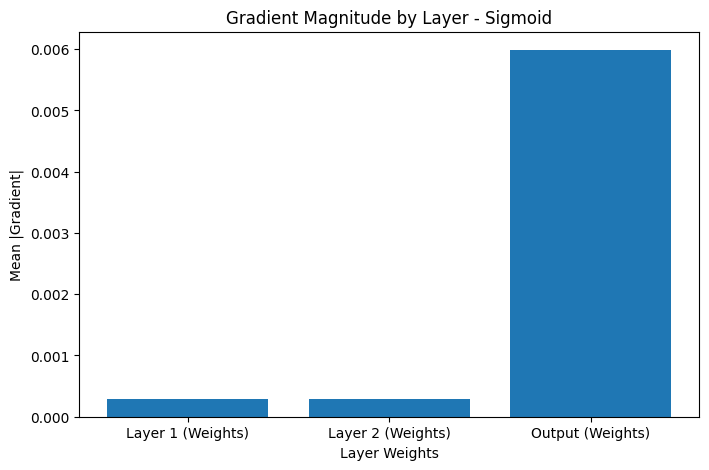

In [34]:
# ==========================================
# TASK 3.4: SIGMOID GRADIENT FLOW
# ==========================================

model_sigmoid = models_activation["sigmoid"]

X_batch = tf.convert_to_tensor(
    X_train.iloc[:64].values,
    dtype=tf.float32
)

y_batch = tf.convert_to_tensor(
    y_train.iloc[:64].values,
    dtype=tf.float32
)

with tf.GradientTape() as tape:
    predictions = model_sigmoid(X_batch, training=True)
    loss_value = keras.losses.binary_crossentropy(
        y_batch,
        tf.squeeze(predictions)
    )
    loss_value = tf.reduce_mean(loss_value)

gradients = tape.gradient(
    loss_value,
    model_sigmoid.trainable_weights
)

gradient_values = []
for i, grad in enumerate(gradients):
    if grad is not None:
        gradient_values.append(
            tf.reduce_mean(tf.abs(grad)).numpy()
        )

# Filter to plot only the weight matrices (even indices: 0, 2, 4), ignoring biases
weight_gradient_values = [gradient_values[0], gradient_values[2], gradient_values[4]]

plt.figure(figsize=(8, 5))
plt.bar(
    ["Layer 1 (Weights)", "Layer 2 (Weights)", "Output (Weights)"],
    weight_gradient_values
)

plt.title("Gradient Magnitude by Layer - Sigmoid")
plt.xlabel("Layer Weights")
plt.ylabel("Mean |Gradient|")
plt.show()

In [35]:
# ==========================================
# TASK 4.1: WEIGHT INITIALIZATION
# ==========================================

initializers = [
    "glorot_uniform",
    "glorot_normal",
    "he_uniform",
    "he_normal",
    "zeros"
]

models_init = {}
histories_init = {}

for initializer in initializers:

    print("\nTraining:", initializer)

    model = build_ann(
        input_dim=X_train.shape[1],
        activation="relu",
        initializer=initializer
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    models_init[initializer] = model
    histories_init[initializer] = history

print("\nAll initializer models trained!")


Training: glorot_uniform


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training: glorot_normal


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training: he_uniform


...


Training: he_normal


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training: zeros


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



All initializer models trained!


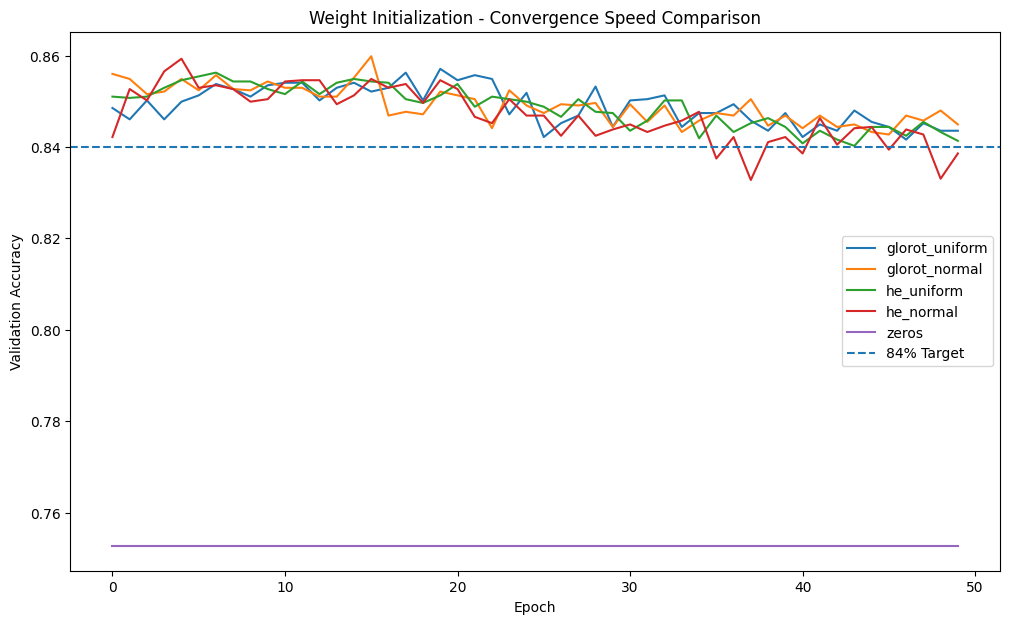

In [36]:
# ==========================================
# TASK 4.3: INITIALIZER CONVERGENCE
# ==========================================

plt.figure(figsize=(12, 7))

for initializer in initializers:

    val_acc = histories_init[initializer].history["val_accuracy"]

    plt.plot(
        val_acc,
        label=initializer
    )

plt.axhline(
    0.84,
    linestyle="--",
    label="84% Target"
)

plt.title(
    "Weight Initialization - Convergence Speed Comparison"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()

plt.show()

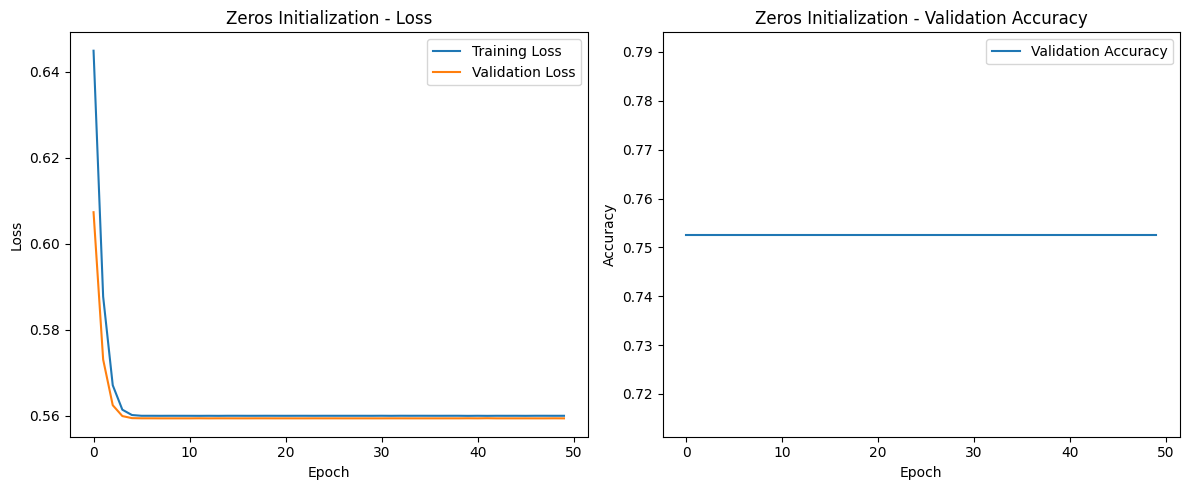

In [37]:
# ==========================================
# TASK 4.4: ZEROS INITIALIZATION FAILURE
# ==========================================

history_zero = histories_init["zeros"]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history_zero.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_zero.history["val_loss"],
    label="Validation Loss"
)

plt.title("Zeros Initialization - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history_zero.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Zeros Initialization - Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


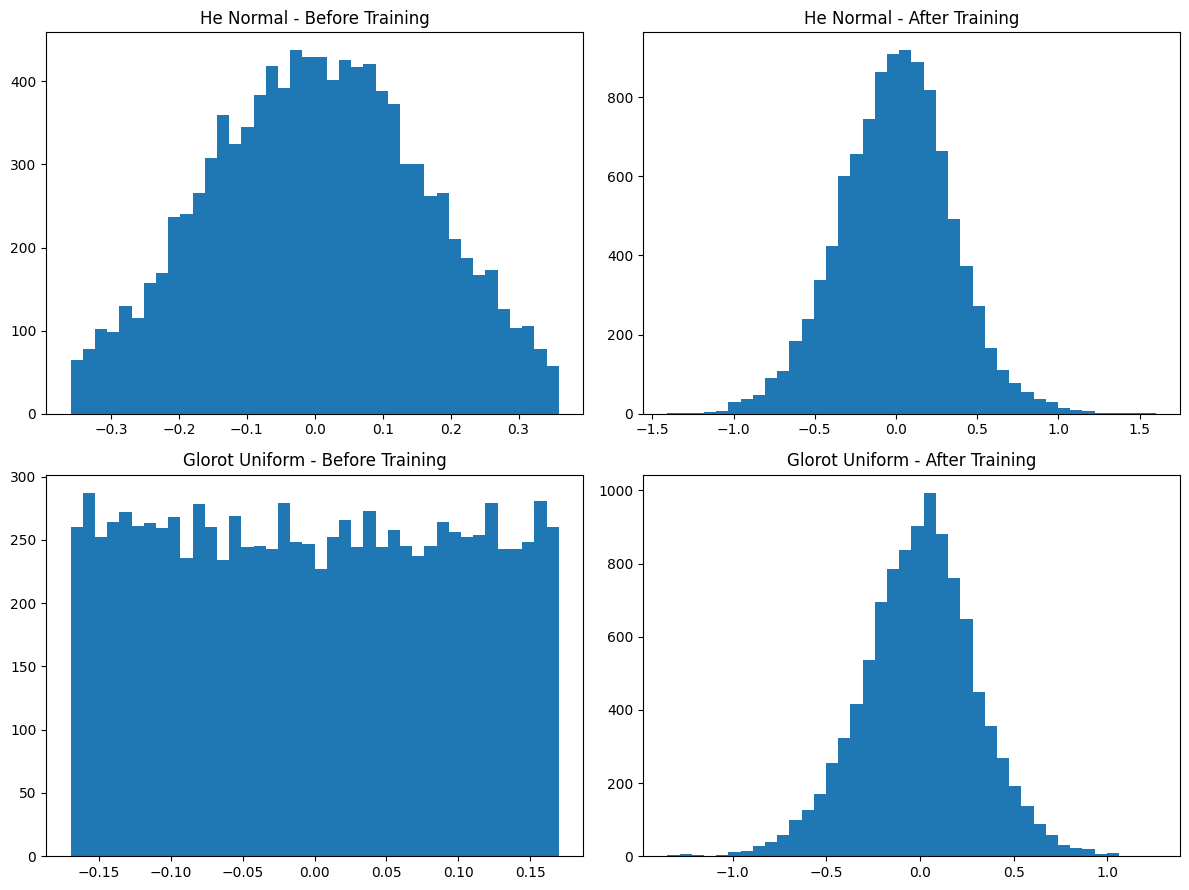

In [38]:
# ==========================================
# TASK 4.5: WEIGHT DISTRIBUTION
# ==========================================

def get_first_layer_weights(model):
    return model.layers[0].get_weights()[0].flatten()


# Create fresh models for initial weights
model_he_before = build_ann(
    input_dim=X_train.shape[1],
    activation="relu",
    initializer="he_normal"
)

model_glorot_before = build_ann(
    input_dim=X_train.shape[1],
    activation="relu",
    initializer="glorot_uniform"
)

he_before = get_first_layer_weights(model_he_before)
glorot_before = get_first_layer_weights(model_glorot_before)

# Trained weights
he_after = get_first_layer_weights(
    models_init["he_normal"]
)

glorot_after = get_first_layer_weights(
    models_init["glorot_uniform"]
)

plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.hist(he_before, bins=40)
plt.title("He Normal - Before Training")

plt.subplot(2, 2, 2)
plt.hist(he_after, bins=40)
plt.title("He Normal - After Training")

plt.subplot(2, 2, 3)
plt.hist(glorot_before, bins=40)
plt.title("Glorot Uniform - Before Training")

plt.subplot(2, 2, 4)
plt.hist(glorot_after, bins=40)
plt.title("Glorot Uniform - After Training")

plt.tight_layout()
plt.show()

In [39]:
# ==========================================
# TASK 5.2: MSE VS BCE
# ==========================================

model_mse = build_ann(
    input_dim=X_train.shape[1],
    activation="relu",
    initializer="he_normal",
    loss="mean_squared_error"
)

history_mse = model_mse.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=0
)

In [40]:
# ==========================================
# TASK 5.2: BCE VS MSE F1
# ==========================================

def get_epoch_f1(model, X_data, y_data):

    probabilities = model.predict(
        X_data,
        verbose=0
    ).flatten()

    predictions = (probabilities > 0.5).astype(int)

    return f1_score(y_data, predictions)


f1_base_value = get_epoch_f1(
    model_base,
    X_test,
    y_test
)

f1_mse_value = get_epoch_f1(
    model_mse,
    X_test,
    y_test
)

print("Baseline BCE F1:", f1_base_value)
print("MSE F1:", f1_mse_value)

Baseline BCE F1: 0.6808035714285714
MSE F1: 0.6671361502347418


In [41]:
# ==========================================
# TASK 5.3: WEIGHTED BCE
# ==========================================

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weight_dict = {
    0: weights[0],
    1: weights[1]
}

print("Class Weights:")
print(class_weight_dict)

Class Weights:
{0: np.float64(0.6647495498144133), 1: np.float64(2.0174548293553425)}


In [42]:
# ==========================================
# TRAIN WEIGHTED BCE MODEL
# ==========================================

model_wbce = build_ann(
    input_dim=X_train.shape[1],
    activation="relu",
    initializer="he_normal",
    loss="binary_crossentropy"
)

history_wbce = model_wbce.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    class_weight=class_weight_dict,
    verbose=0
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [43]:
# ==========================================
# TASK 5.3: WEIGHTED BCE EVALUATION
# ==========================================

y_wbce_prob = model_wbce.predict(
    X_test,
    verbose=0
).flatten()

y_wbce_pred = (
    y_wbce_prob > 0.5
).astype(int)

precision_wbce = precision_score(
    y_test,
    y_wbce_pred
)

recall_wbce = recall_score(
    y_test,
    y_wbce_pred
)

f1_wbce = f1_score(
    y_test,
    y_wbce_pred
)

print("Weighted BCE")
print("----------------")
print("Precision:", precision_wbce)
print("Recall:", recall_wbce)
print("F1:", f1_wbce)

Weighted BCE
----------------
Precision: 0.5531978481769276
Recall: 0.8256021409455843
F1: 0.6624910522548317


In [44]:
# ==========================================
# TASK 5.4: FOCAL LOSS
# ==========================================

def focal_loss(gamma=2.0, alpha=0.25):

    def loss(y_true, y_pred):

        y_pred = tf.clip_by_value(
            y_pred,
            1e-7,
            1 - 1e-7
        )

        bce = (
            -y_true * tf.math.log(y_pred)
            - (1 - y_true) * tf.math.log(1 - y_pred)
        )

        weight = (
            alpha * y_true * (1 - y_pred) ** gamma
            +
            (1 - alpha) * (1 - y_true) * y_pred ** gamma
        )

        return tf.reduce_mean(weight * bce)

    return loss

In [45]:
# ==========================================
# TRAIN FOCAL LOSS MODEL
# ==========================================

model_focal = build_ann(
    input_dim=X_train.shape[1],
    activation="relu",
    initializer="he_normal",
    loss=focal_loss()
)

history_focal = model_focal.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=0
)

y_focal_prob = model_focal.predict(
    X_test,
    verbose=0
).flatten()

y_focal_pred = (
    y_focal_prob > 0.5
).astype(int)

print("Focal Loss")
print("----------------")
print("Precision:", precision_score(y_test, y_focal_pred))
print("Recall:", recall_score(y_test, y_focal_pred))
print("F1:", f1_score(y_test, y_focal_pred))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Focal Loss
----------------
Precision: 0.7871244635193133
Recall: 0.4090098126672614
F1: 0.5383034928089228


In [46]:
# ==========================================
# TASK 6.1: BATCH NORMALIZATION MODEL
# ==========================================

model_bn = keras.Sequential([

    layers.Dense(
        128,
        kernel_initializer="he_normal",
        input_shape=(X_train.shape[1],)
    ),

    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Dense(
        64,
        kernel_initializer="he_normal"
    ),

    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

model_bn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_bn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_45 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [48]:
# ==========================================
# TASK 6.3: TRAIN BATCH NORMALIZATION
# ==========================================

history_bn = model_bn.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8311 - loss: 0.3598 - val_accuracy: 0.8477 - val_loss: 0.3244
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8505 - loss: 0.3200 - val_accuracy: 0.8532 - val_loss: 0.3203
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8509 - loss: 0.3155 - val_accuracy: 0.8494 - val_loss: 0.3225
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8560 - loss: 0.3098 - val_accuracy: 0.8452 - val_loss: 0.3274
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8566 - loss: 0.3073 - val_accuracy: 0.8549 - val_loss: 0.3197
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8576 - loss: 0.3042 - val_accuracy: 0.8521 - val_loss: 0.3234
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8607 - loss: 0.3012 - val_accuracy: 0.8507 - val_loss: 0.3202
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8606 - loss: 0.3000 - val_accuracy: 0.

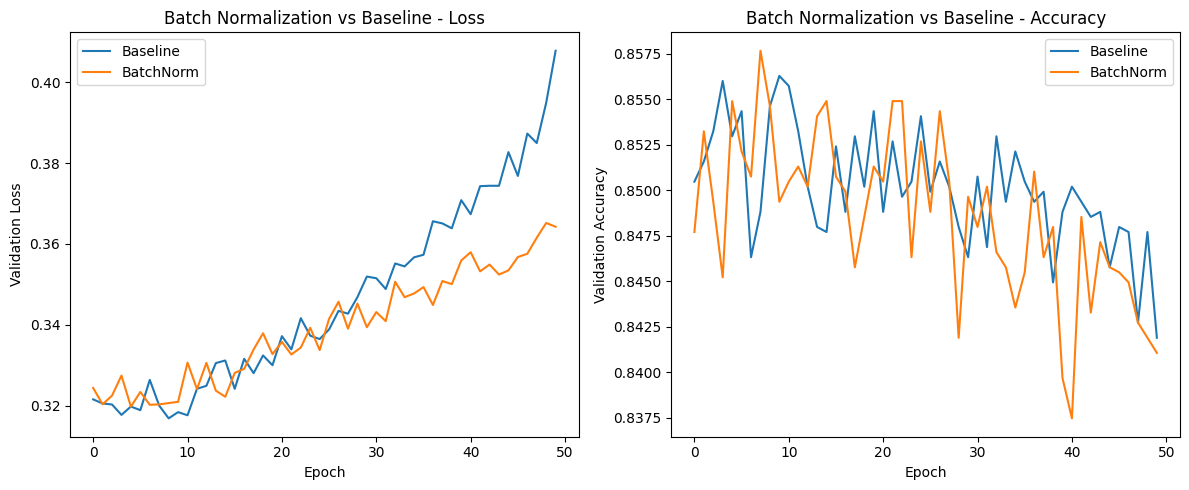

In [49]:
# ==========================================
# TASK 6.3: BN VS BASELINE
# ==========================================

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)

plt.plot(
    history_base.history["val_loss"],
    label="Baseline"
)

plt.plot(
    history_bn.history["val_loss"],
    label="BatchNorm"
)

plt.title("Batch Normalization vs Baseline - Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()


# Accuracy
plt.subplot(1, 2, 2)

plt.plot(
    history_base.history["val_accuracy"],
    label="Baseline"
)

plt.plot(
    history_bn.history["val_accuracy"],
    label="BatchNorm"
)

plt.title("Batch Normalization vs Baseline - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [50]:
# ==========================================
# TASK 6.3: BATCHNORM EVALUATION
# ==========================================

y_bn_prob = model_bn.predict(
    X_test,
    verbose=0
).flatten()

y_bn_pred = (
    y_bn_prob > 0.5
).astype(int)

print("BatchNorm Accuracy:",
      np.mean(y_bn_pred == y_test))

print("BatchNorm F1:",
      f1_score(y_test, y_bn_pred))

BatchNorm Accuracy: 0.8420121614151465
BatchNorm F1: 0.6636855730760178


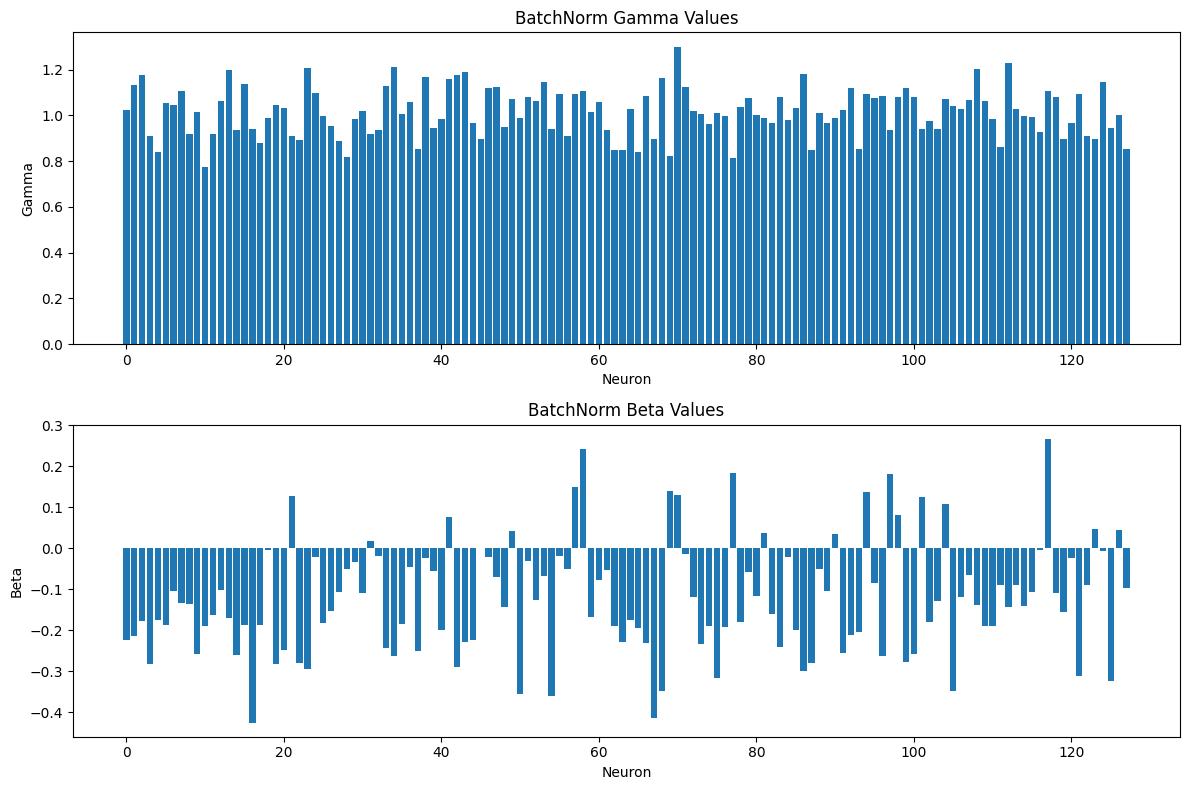

In [51]:
# ==========================================
# TASK 6.5: GAMMA AND BETA
# ==========================================

bn_layer = model_bn.layers[1]

gamma = bn_layer.gamma.numpy()
beta = bn_layer.beta.numpy()

plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)

plt.bar(
    range(len(gamma)),
    gamma
)

plt.title("BatchNorm Gamma Values")
plt.xlabel("Neuron")
plt.ylabel("Gamma")


plt.subplot(2, 1, 2)

plt.bar(
    range(len(beta)),
    beta
)

plt.title("BatchNorm Beta Values")
plt.xlabel("Neuron")
plt.ylabel("Beta")

plt.tight_layout()
plt.show()

In [52]:
# ==========================================
# TASK 7.1: OPTIMIZER COMPARISON
# ==========================================

optimizer_configs = {

    "SGD": keras.optimizers.SGD(),

    "SGD Momentum": keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),

    "RMSprop": keras.optimizers.RMSprop(),

    "Adam": keras.optimizers.Adam(),

    "Adam Explicit": keras.optimizers.Adam(
        learning_rate=0.001,
        beta_1=0.9,
        beta_2=0.999
    )
}

models_optimizer = {}
histories_optimizer = {}

for name, optimizer in optimizer_configs.items():

    print("\nTraining:", name)

    model = build_ann(
        input_dim=X_train.shape[1],
        activation="relu",
        initializer="he_normal",
        use_batch_norm=True,
        optimizer=optimizer,
        loss="binary_crossentropy"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    models_optimizer[name] = model
    histories_optimizer[name] = history


Training: SGD


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training: SGD Momentum


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training: RMSprop


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training: Adam


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training: Adam Explicit


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


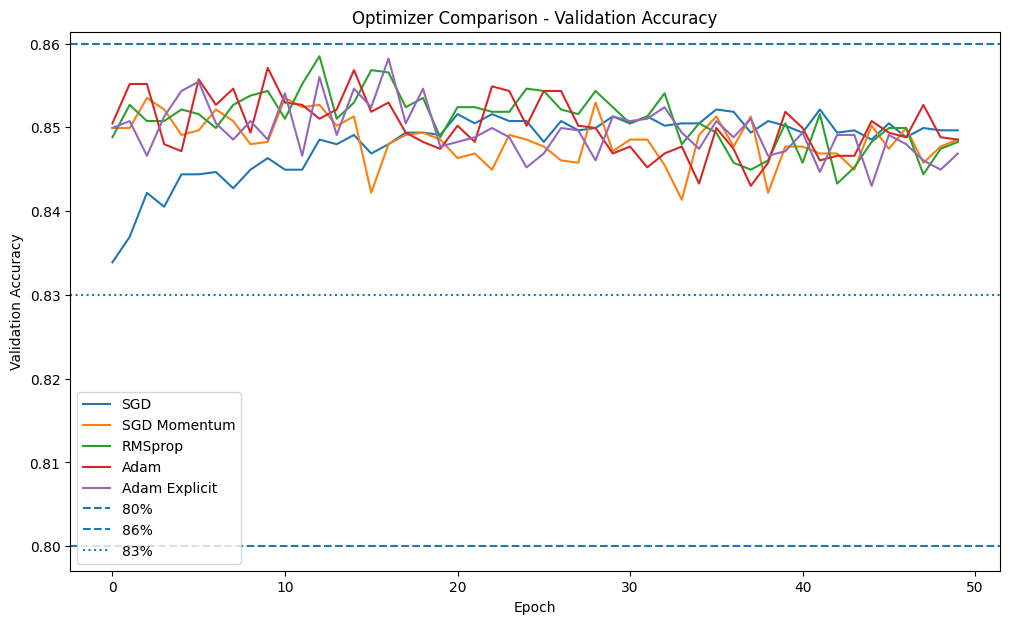

In [53]:
# ==========================================
# TASK 7.2: OPTIMIZER CONVERGENCE
# ==========================================

plt.figure(figsize=(12, 7))

for name in histories_optimizer:

    val_acc = histories_optimizer[name].history["val_accuracy"]

    plt.plot(
        val_acc,
        label=name
    )

plt.axhline(
    0.80,
    linestyle="--",
    label="80%"
)

plt.axhline(
    0.86,
    linestyle="--",
    label="86%"
)

plt.axhline(
    0.83,
    linestyle=":",
    label="83%"
)

plt.title(
    "Optimizer Comparison - Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()

plt.show()

In [54]:
# ==========================================
# TASK 7.5: FINAL COMBINED ANN
# ==========================================

final_model = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="adam",
    loss="binary_crossentropy"
)

final_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_63 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [55]:
# ==========================================
# TRAIN FINAL MODEL
# ==========================================

history_final = final_model.fit(
    X_train,
    y_train,
    epochs=80,
    batch_size=64,
    validation_split=0.1,
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7877 - loss: 0.4076 - val_accuracy: 0.8046 - val_loss: 0.4001
Epoch 2/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8085 - loss: 0.3772 - val_accuracy: 0.7985 - val_loss: 0.3979
Epoch 3/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8109 - loss: 0.3719 - val_accuracy: 0.8004 - val_loss: 0.3917
Epoch 4/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8124 - loss: 0.3680 - val_accuracy: 0.7955 - val_loss: 0.3992
Epoch 5/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8134 - loss: 0.3642 - val_accuracy: 0.7985 - val_loss: 0.3862
Epoch 6/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8167 - loss: 0.3607 - val_accuracy: 0.8049 - val_loss: 0.3852
Epoch 7/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8185 - loss: 0.3581 - val_accuracy: 0.8040 - val_loss: 0.3862
Epoch 8/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8194 - loss: 0.3538 - val_accuracy: 0.

In [56]:
# ==========================================
# FINAL MODEL EVALUATION
# ==========================================

y_final_prob = final_model.predict(
    X_test,
    verbose=0
).flatten()

y_final_pred = (
    y_final_prob > 0.5
).astype(int)

final_accuracy = np.mean(
    y_final_pred == y_test
)

final_precision = precision_score(
    y_test,
    y_final_pred
)

final_recall = recall_score(
    y_test,
    y_final_pred
)

final_f1 = f1_score(
    y_test,
    y_final_pred
)

final_auc = roc_auc_score(
    y_test,
    y_final_prob
)

print("FINAL MODEL RESULTS")
print("==========================")
print("Accuracy :", final_accuracy)
print("Precision:", final_precision)
print("Recall   :", final_recall)
print("F1 Score :", final_f1)
print("ROC-AUC  :", final_auc)

FINAL MODEL RESULTS
Accuracy : 0.8009950248756219
Precision: 0.5675840978593272
Recall   : 0.8278322925958965
F1 Score : 0.6734397677793904
ROC-AUC  : 0.8954876456220514


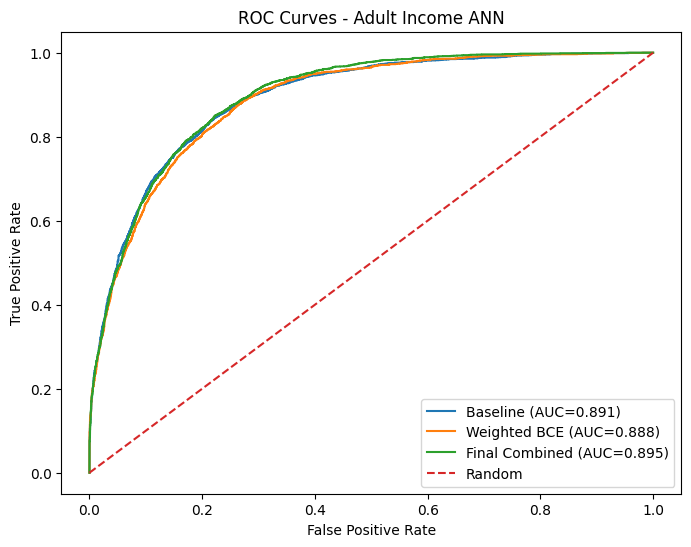

In [57]:
# ==========================================
# TASK 7.6: ROC CURVE
# ==========================================

fpr_base, tpr_base, _ = roc_curve(
    y_test,
    y_pred_prob
)

fpr_wbce, tpr_wbce, _ = roc_curve(
    y_test,
    y_wbce_prob
)

fpr_final, tpr_final, _ = roc_curve(
    y_test,
    y_final_prob
)

auc_base = roc_auc_score(
    y_test,
    y_pred_prob
)

auc_wbce = roc_auc_score(
    y_test,
    y_wbce_prob
)

auc_final = roc_auc_score(
    y_test,
    y_final_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_base,
    tpr_base,
    label=f"Baseline (AUC={auc_base:.3f})"
)

plt.plot(
    fpr_wbce,
    tpr_wbce,
    label=f"Weighted BCE (AUC={auc_wbce:.3f})"
)

plt.plot(
    fpr_final,
    tpr_final,
    label=f"Final Combined (AUC={auc_final:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.title("ROC Curves - Adult Income ANN")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

In [58]:
# ==========================================
# TASK 7.6: FULL RESULTS TABLE
# ==========================================

results = []

# Baseline
results.append([
    "Baseline",
    "ReLU",
    "Glorot Uniform",
    "BCE",
    "No",
    "Adam",
    precision_base,
    recall_base,
    f1_base,
    auc_base
])

# Weighted BCE
results.append([
    "Weighted BCE",
    "ReLU",
    "He Normal",
    "Weighted BCE",
    "No",
    "Adam",
    precision_wbce,
    recall_wbce,
    f1_wbce,
    auc_wbce
])

# Focal Loss
results.append([
    "Focal Loss",
    "ReLU",
    "He Normal",
    "Focal Loss",
    "No",
    "Adam",
    precision_score(y_test, y_focal_pred),
    recall_score(y_test, y_focal_pred),
    f1_score(y_test, y_focal_pred),
    roc_auc_score(y_test, y_focal_prob)
])

# BatchNorm
results.append([
    "BatchNorm",
    "ReLU",
    "He Normal",
    "BCE",
    "Yes",
    "Adam",
    precision_score(y_test, y_bn_pred),
    recall_score(y_test, y_bn_pred),
    f1_score(y_test, y_bn_pred),
    roc_auc_score(y_test, y_bn_prob)
])

# Final
results.append([
    "Final Combined",
    "ReLU",
    "He Normal",
    "BCE",
    "Yes",
    "Adam",
    final_precision,
    final_recall,
    final_f1,
    final_auc
])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Activation",
        "Init",
        "Loss",
        "BatchNorm",
        "Optimizer",
        "Precision(1)",
        "Recall(1)",
        "F1(1)",
        "ROC-AUC"
    ]
)

display(results_df)

,Model,Activation,Init,Loss,BatchNorm,Optimizer,Precision(1),Recall(1),F1(1),ROC-AUC
0,Baseline,ReLU,Glorot Uniform,BCE,No,Adam,0.681412,0.680196,0.680804,0.891356
1,Weighted BCE,ReLU,He Normal,Weighted BCE,No,Adam,0.553198,0.825602,0.662491,0.887636
2,Focal Loss,ReLU,He Normal,Focal Loss,No,Adam,0.787124,0.409010,0.538303,0.887341
3,BatchNorm,ReLU,He Normal,BCE,Yes,Adam,0.702541,0.628903,0.663686,0.895369
4,Final Combined,ReLU,He Normal,BCE,Yes,Adam,0.567584,0.827832,0.673440,0.895488
